# 4. Model CNN-SVM

Model má dve časti, ktoré sa trénujú oddelene:
1. **CNN** – príznaky ResNet18 z notebooku 2 (512 čísel na snímku),
2. **SVM** (support vector machine) – klasifikátor, ktorý hľadá hranicu medzi triedami
   v priestore príznakov.

SVM potrebuje jeden vektor na klip, preto príznaky 16 snímok **spriemerujeme**.
Poradie snímok sa tým stráca.

V každom delení sa typ kernelu SVM (lineárny / RBF) a jeho parametre vyberú
krížovou validáciou iba na trénovacích dátach.

**Hodnotenie** (rovnaké pre všetky modely, `har/evaluation.py`):
- 10 delení na trénovacie a testovacie dáta podľa filmu (notebook 1),
- model sa v každom delení trénuje iba na trénovacích dátach,
- metriky na testovacích dátach:
  - **presnosť** (*accuracy*) – koľko % testovacích klipov model zaradil správne,
  - **správne &lt;trieda&gt;** (*recall*) – koľko % klipov danej triedy model zaradil správne.

In [1]:
import numpy as np
import pandas as pd

from har.config import INDEX_FILE
from har.evaluation import evaluate_svm, plot_confusion, save_predictions, summary

df = pd.read_csv(INDEX_FILE)
feats = np.load("features_resnet.npy")     # (klipy, 16, 512)
X = feats.mean(axis=1)                     # priemer cez snímky -> (klipy, 512)

## Hodnotenie

In [2]:
pred = evaluate_svm(X, df)
save_predictions(pred, "cnn_svm")
summary(pred, "CNN-SVM")

,presnosť (accuracy),správne eat (recall),správne clap (recall)
CNN-SVM,87 % ± 7 %,93 % ± 6 %,82 % ± 11 %


## Chyby modelu

Matica zámen (*confusion matrix*) zo všetkých 10 delení. Riadok = skutočná trieda,
stĺpec = predpoveď modelu.
- vľavo: počet testovacích klipov (súčet cez 10 delení, každý klip je v teste viackrát),
- vpravo: % klipov danej skutočnej triedy (súčet v riadku je 100 %).

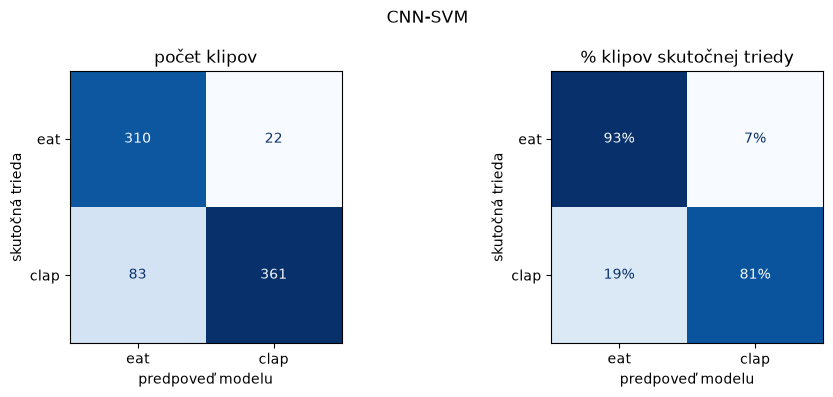

In [3]:
plot_confusion(pred, "CNN-SVM")